In [1]:
# ============================================
# CustomerLens - Data Audit & EDA
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================
# LOAD RAW DATASET
# ============================================

DATA_PATH = Path("../data/raw/Mall_Customers.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

display(df.head())

Dataset loaded successfully.
Rows    : 200
Columns : 5


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# ============================================
# DATASET STRUCTURE
# ============================================

print("Column names:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

print("\nData types:")
print(df.dtypes)

print("\nDataset shape:")
print(df.shape)

Column names:
1. CustomerID
2. Gender
3. Age
4. Annual Income (k$)
5. Spending Score (1-100)

Data types:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Dataset shape:
(200, 5)


In [4]:
# ============================================
# MISSING VALUE AUDIT
# ============================================

missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

display(missing)

print("Total missing values:", df.isnull().sum().sum())

,Missing Count,Missing Percentage
CustomerID,0,0.0
Gender,0,0.0
Age,0,0.0
Annual Income (k$),0,0.0
Spending Score (1-100),0,0.0


Total missing values: 0


In [5]:
# ============================================
# DUPLICATE AUDIT
# ============================================

duplicate_rows = df.duplicated().sum()
duplicate_customer_ids = df["CustomerID"].duplicated().sum()

print("Duplicate rows:", duplicate_rows)
print("Duplicate Customer IDs:", duplicate_customer_ids)

Duplicate rows: 0
Duplicate Customer IDs: 0


In [6]:
# ============================================
# STATISTICAL SUMMARY
# ============================================

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0


Gender distribution:


Gender
Female    112
Male       88
Name: count, dtype: int64

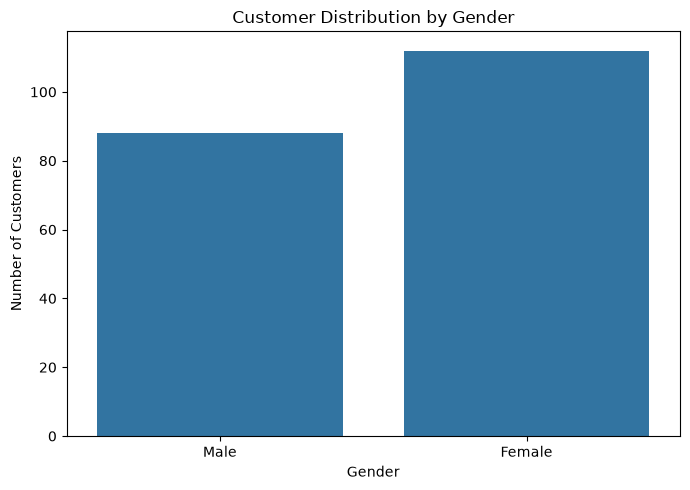

In [7]:
# ============================================
# GENDER DISTRIBUTION
# ============================================

print("Gender distribution:")
display(df["Gender"].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Gender"
)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

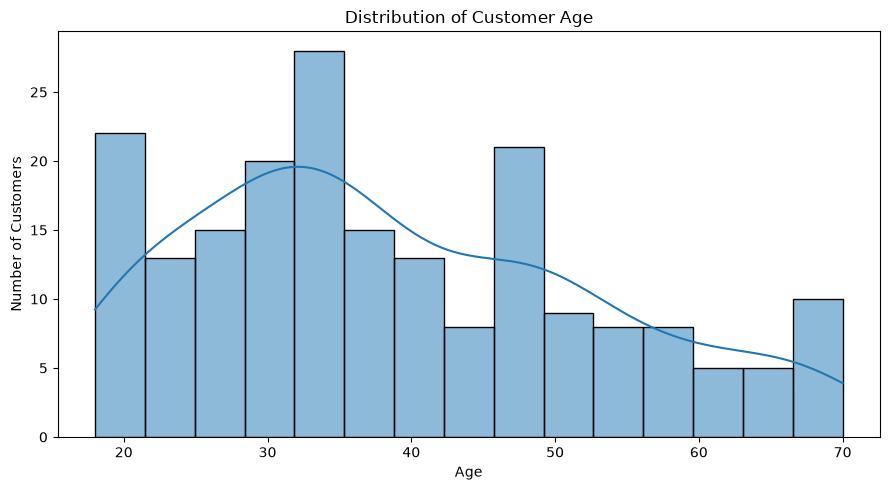

In [8]:
# ============================================
# AGE DISTRIBUTION
# ============================================

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

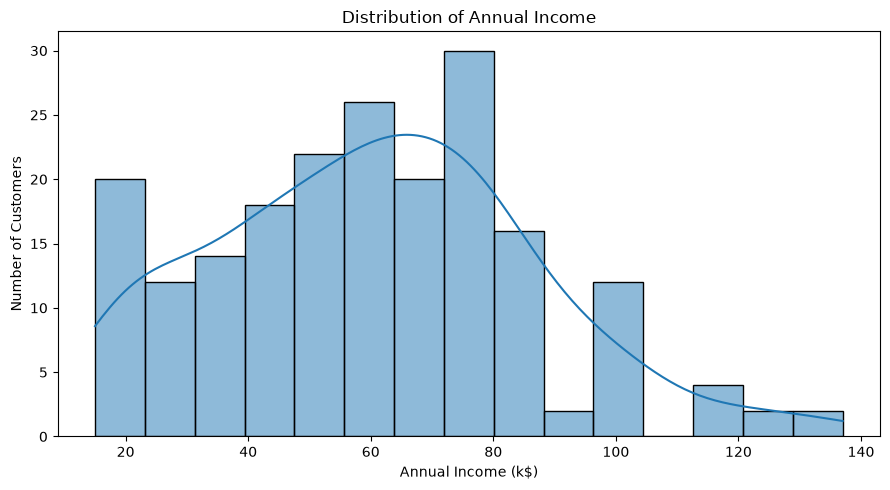

In [9]:
# ============================================
# ANNUAL INCOME DISTRIBUTION
# ============================================

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Annual Income (k$)",
    bins=15,
    kde=True
)

plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

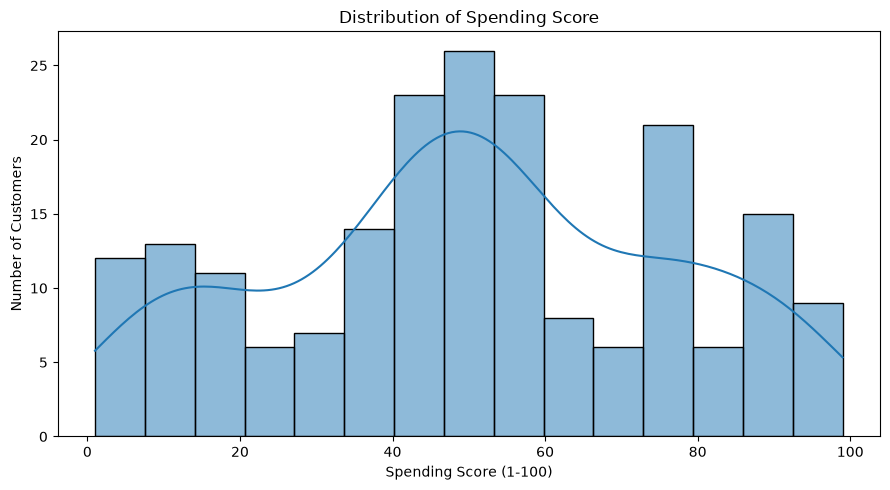

In [10]:
# ============================================
# SPENDING SCORE DISTRIBUTION
# ============================================

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Spending Score (1-100)",
    bins=15,
    kde=True
)

plt.title("Distribution of Spending Score")
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

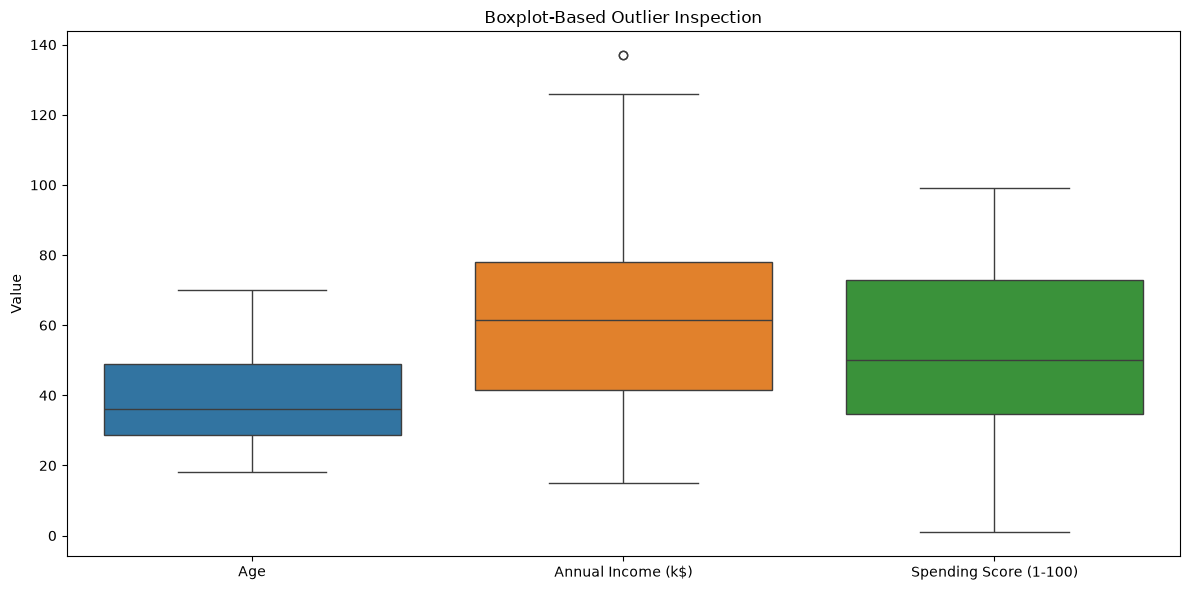

In [11]:
# ============================================
# OUTLIER INSPECTION
# ============================================

numeric_features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[numeric_features]
)

plt.title("Boxplot-Based Outlier Inspection")
plt.ylabel("Value")
plt.tight_layout()
plt.show()

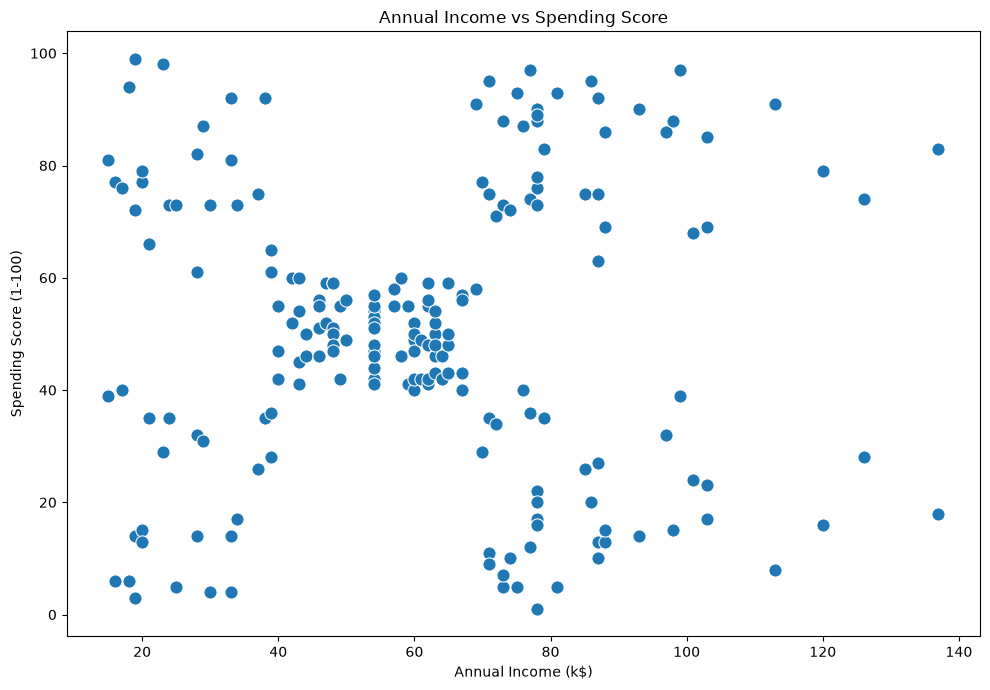

In [12]:
# ============================================
# REQUIRED VISUALIZATION
# INCOME VS SPENDING SCORE
# ============================================

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    s=90
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

In [13]:
# ============================================
# CORRELATION ANALYSIS
# ============================================

correlation_features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

correlation_matrix = df[correlation_features].corr()

display(correlation_matrix)

,Age,Annual Income (k$),Spending Score (1-100)
Age,1.000000,-0.012398,-0.327227
Annual Income (k$),-0.012398,1.000000,0.009903
Spending Score (1-100),-0.327227,0.009903,1.000000


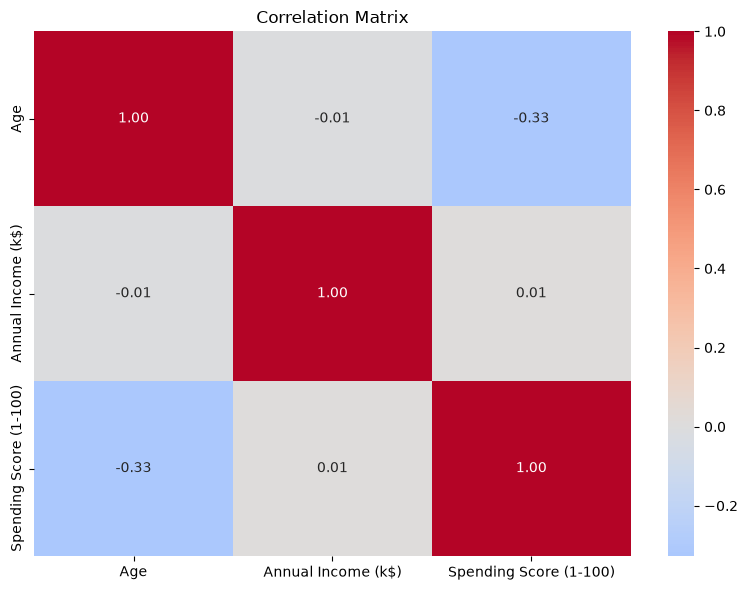

In [14]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [15]:
# ============================================
# CLUSTERING FEATURE SELECTION
# ============================================

CLUSTER_FEATURES = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[CLUSTER_FEATURES].copy()

print("Selected clustering features:")
print(CLUSTER_FEATURES)

print("\nFeature matrix shape:")
print(X.shape)

display(X.head())

Selected clustering features:
['Annual Income (k$)', 'Spending Score (1-100)']

Feature matrix shape:
(200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [16]:
## Feature Selection Rationale

CustomerID is an identifier and does not represent customer behavior. Therefore, it is excluded from clustering.

The primary clustering features are:

- Annual Income (k$)
- Spending Score (1-100)

These features are selected because they directly represent the dimensions required for customer segmentation and allow the required Income vs Spending Score visualization.

Gender and Age are retained in the original dataset for demographic profiling after clustering, but they are not used as primary clustering dimensions.

SyntaxError: invalid syntax (3368915593.py, line 3)

In [17]:
# ============================================
# FEATURE SCALING
# ============================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled_array = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=CLUSTER_FEATURES,
    index=X.index
)

print("Scaled feature matrix:")
display(X_scaled.head())

Scaled feature matrix:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


In [18]:
print("Scaled feature means:")
display(X_scaled.mean())

print("\nScaled feature standard deviations:")
display(X_scaled.std())

Scaled feature means:


Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64


Scaled feature standard deviations:


Annual Income (k$)        1.002509
Spending Score (1-100)    1.002509
dtype: float64

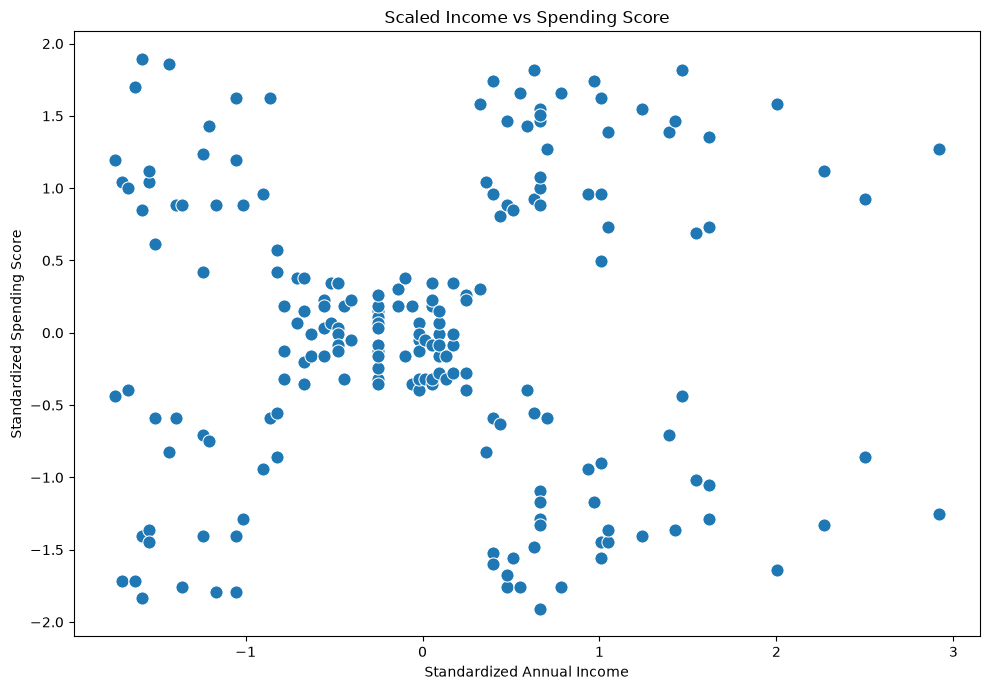

In [19]:
# ============================================
# SCALED FEATURE VISUALIZATION
# ============================================

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_scaled["Annual Income (k$)"],
    y=X_scaled["Spending Score (1-100)"],
    s=90
)

plt.title("Scaled Income vs Spending Score")
plt.xlabel("Standardized Annual Income")
plt.ylabel("Standardized Spending Score")
plt.tight_layout()
plt.show()

In [20]:
# ============================================
# SAVE PROCESSED FEATURES
# ============================================

PROCESSED_PATH = Path("../data/processed")

PROCESSED_PATH.mkdir(parents=True, exist_ok=True)

processed_df = df.copy()

processed_df.to_csv(
    PROCESSED_PATH / "customers_audited.csv",
    index=False
)

X_scaled.to_csv(
    PROCESSED_PATH / "clustering_features_scaled.csv",
    index=False
)

print("Processed datasets saved successfully.")

Processed datasets saved successfully.


In [21]:
# ============================================
# PHASE 1 CHECKPOINT
# ============================================

print("========== CUSTOMERLENS PHASE 1 CHECKPOINT ==========")
print(f"Raw dataset shape       : {df.shape}")
print(f"Missing values          : {df.isnull().sum().sum()}")
print(f"Duplicate rows          : {df.duplicated().sum()}")
print(f"Clustering features     : {CLUSTER_FEATURES}")
print(f"Feature matrix shape    : {X.shape}")
print(f"Scaled matrix shape     : {X_scaled.shape}")
print("======================================================")

========== CUSTOMERLENS PHASE 1 CHECKPOINT ==========
Raw dataset shape       : (200, 5)
Missing values          : 0
Duplicate rows          : 0
Clustering features     : ['Annual Income (k$)', 'Spending Score (1-100)']
Feature matrix shape    : (200, 2)
Scaled matrix shape     : (200, 2)


In [22]:
# ============================================
# PHASE 2 - K-MEANS OPTIMAL K EXPERIMENT
# ============================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

K_VALUES = range(2, 11)

kmeans_results = []

for k in K_VALUES:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    inertia = model.inertia_
    silhouette = silhouette_score(X_scaled, labels)
    davies_bouldin = davies_bouldin_score(X_scaled, labels)

    kmeans_results.append({
        "k": k,
        "inertia": inertia,
        "silhouette": silhouette,
        "davies_bouldin": davies_bouldin
    })

kmeans_results_df = pd.DataFrame(kmeans_results)

display(kmeans_results_df)

,k,inertia,silhouette,davies_bouldin
0,2,269.691012,0.321271,1.266954
1,3,157.704008,0.466585,0.716482
2,4,108.921317,0.493907,0.709556
3,5,65.568408,0.554657,0.572236
4,6,55.057348,0.539880,0.654567
5,7,44.864756,0.528149,0.714784
6,8,37.148117,0.456721,0.757911
7,9,32.392268,0.457085,0.763226
8,10,29.685788,0.436212,0.764524


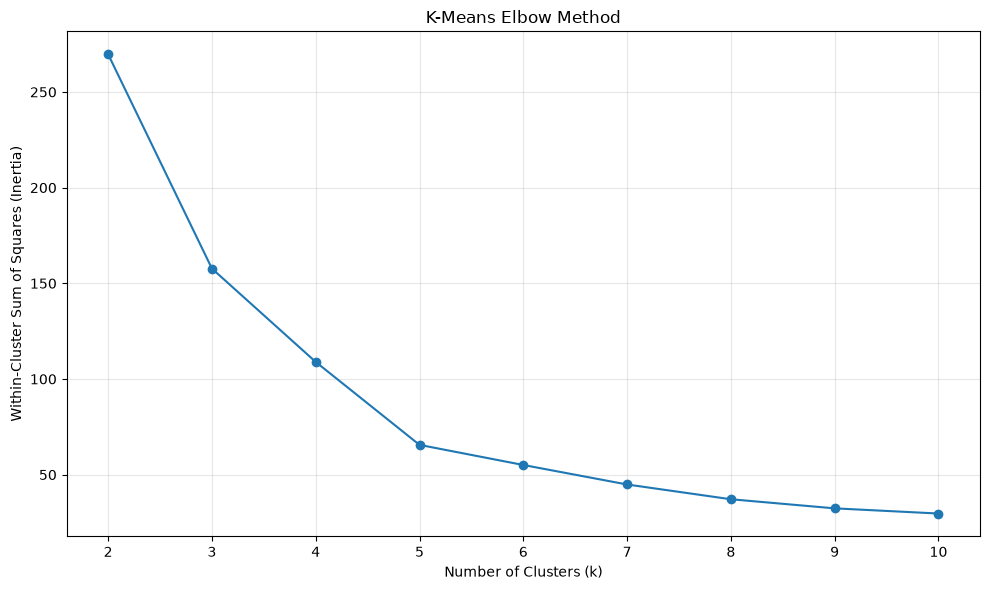

In [23]:
# ============================================
# K-MEANS ELBOW METHOD
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    kmeans_results_df["k"],
    kmeans_results_df["inertia"],
    marker="o"
)

plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.xticks(list(K_VALUES))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

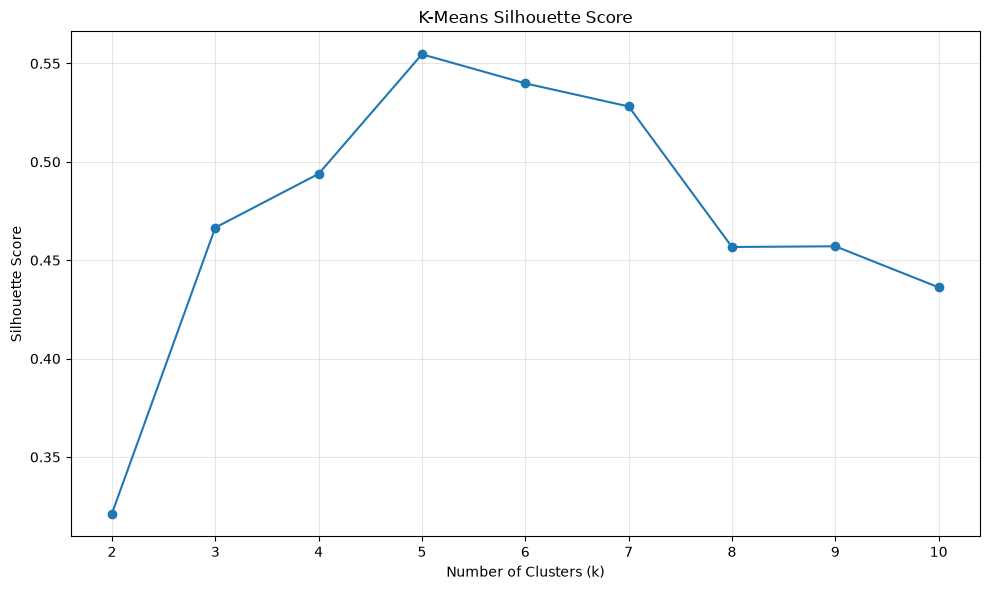

In [24]:
# ============================================
# K-MEANS SILHOUETTE SCORE
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    kmeans_results_df["k"],
    kmeans_results_df["silhouette"],
    marker="o"
)

plt.title("K-Means Silhouette Score")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(K_VALUES))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

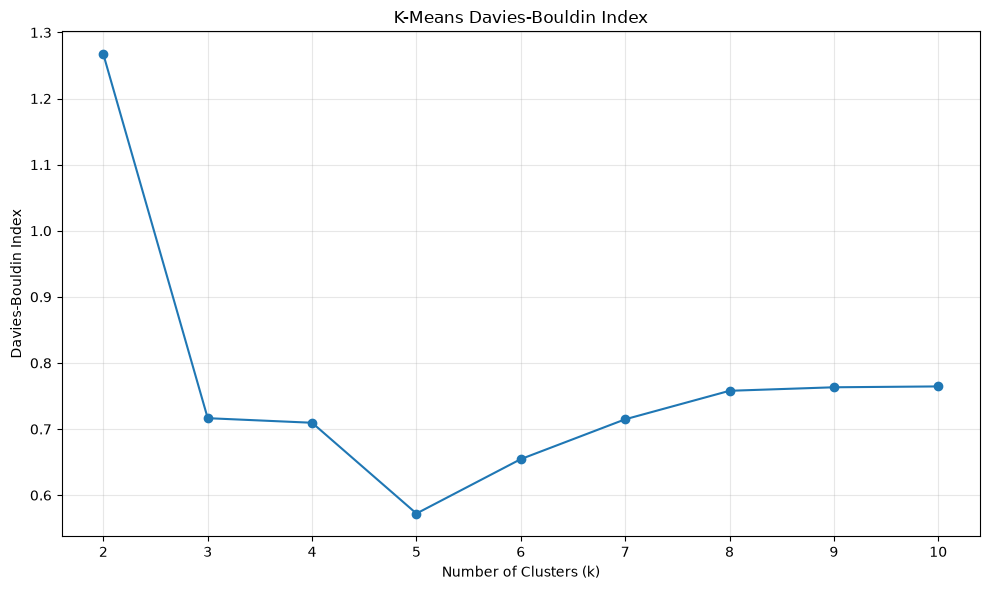

In [25]:
# ============================================
# K-MEANS DAVIES-BOULDIN INDEX
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    kmeans_results_df["k"],
    kmeans_results_df["davies_bouldin"],
    marker="o"
)

plt.title("K-Means Davies-Bouldin Index")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Davies-Bouldin Index")
plt.xticks(list(K_VALUES))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# ============================================
# K-MEANS METRIC SUMMARY
# ============================================

best_silhouette_k = kmeans_results_df.loc[
    kmeans_results_df["silhouette"].idxmax(),
    "k"
]

best_davies_bouldin_k = kmeans_results_df.loc[
    kmeans_results_df["davies_bouldin"].idxmin(),
    "k"
]

print("K with highest silhouette score:", best_silhouette_k)
print("K with lowest Davies-Bouldin index:", best_davies_bouldin_k)

K with highest silhouette score: 5
K with lowest Davies-Bouldin index: 5


In [27]:
# ============================================
# SAVE K-MEANS K-SELECTION RESULTS
# ============================================

RESULTS_PATH = Path("../artifacts/results")
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

kmeans_results_df.to_csv(
    RESULTS_PATH / "kmeans_optimal_k_results.csv",
    index=False
)

print("K-Means optimal-k results saved.")

K-Means optimal-k results saved.


In [28]:
display(kmeans_results_df)

,k,inertia,silhouette,davies_bouldin
0,2,269.691012,0.321271,1.266954
1,3,157.704008,0.466585,0.716482
2,4,108.921317,0.493907,0.709556
3,5,65.568408,0.554657,0.572236
4,6,55.057348,0.539880,0.654567
5,7,44.864756,0.528149,0.714784
6,8,37.148117,0.456721,0.757911
7,9,32.392268,0.457085,0.763226
8,10,29.685788,0.436212,0.764524


In [29]:
# ============================================
# PHASE 3 - K-MEDOIDS / PAM
# ============================================

from sklearn.metrics import pairwise_distances

distance_matrix = pairwise_distances(
    X_scaled.values,
    metric="euclidean"
)

print("Distance matrix shape:", distance_matrix.shape)

Distance matrix shape: (200, 200)


In [30]:
# ============================================
# PAM K-MEDOIDS IMPLEMENTATION
# ============================================

def pam_kmedoids(
    X,
    k,
    max_iter=100
):
    """
    Partitioning Around Medoids (PAM)

    Parameters
    ----------
    X : numpy.ndarray
        Feature matrix.

    k : int
        Number of medoids/clusters.

    max_iter : int
        Maximum number of swap iterations.

    Returns
    -------
    medoids : numpy.ndarray
        Indices of selected medoid points.

    labels : numpy.ndarray
        Cluster label for every observation.

    total_cost : float
        Sum of distances from each point
        to its nearest medoid.
    """

    n = len(X)

    if k >= n:
        raise ValueError("k must be smaller than number of observations.")

    # ----------------------------------------
    # Step 1: BUILD INITIAL MEDOIDS
    # ----------------------------------------

    medoids = []

    # First medoid:
    # choose point with minimum total distance
    first_medoid = np.argmin(distance_matrix.sum(axis=1))
    medoids.append(int(first_medoid))

    # Select remaining medoids greedily
    while len(medoids) < k:

        current_distances = distance_matrix[:, medoids].min(axis=1)

        best_candidate = None
        best_cost = np.inf

        for candidate in range(n):

            if candidate in medoids:
                continue

            candidate_distances = np.minimum(
                current_distances,
                distance_matrix[:, candidate]
            )

            candidate_cost = candidate_distances.sum()

            if candidate_cost < best_cost:
                best_cost = candidate_cost
                best_candidate = candidate

        medoids.append(int(best_candidate))

    medoids = np.array(medoids, dtype=int)

    # ----------------------------------------
    # Step 2: SWAP PHASE
    # ----------------------------------------

    for iteration in range(max_iter):

        current_distances = distance_matrix[:, medoids].min(axis=1)
        current_cost = current_distances.sum()

        best_swap = None
        best_cost = current_cost

        medoid_set = set(medoids)

        for medoid in medoids:

            for candidate in range(n):

                if candidate in medoid_set:
                    continue

                trial_medoids = medoids.copy()

                trial_medoids[
                    trial_medoids == medoid
                ] = candidate

                trial_distances = distance_matrix[
                    :, trial_medoids
                ].min(axis=1)

                trial_cost = trial_distances.sum()

                if trial_cost < best_cost - 1e-12:
                    best_cost = trial_cost
                    best_swap = (medoid, candidate)

        # No improving swap found
        if best_swap is None:
            break

        # Apply best swap
        old_medoid, new_medoid = best_swap

        medoids[
            medoids == old_medoid
        ] = new_medoid

    # ----------------------------------------
    # Step 3: FINAL ASSIGNMENT
    # ----------------------------------------

    final_distances = distance_matrix[:, medoids]

    labels = np.argmin(
        final_distances,
        axis=1
    )

    total_cost = final_distances[
        np.arange(n),
        labels
    ].sum()

    return medoids, labels, total_cost

In [31]:
# ============================================
# TEST PAM WITH K = 5
# ============================================

test_medoids, test_labels, test_cost = pam_kmedoids(
    X_scaled.values,
    k=5
)

print("Selected medoid indices:")
print(test_medoids)

print("\nMedoid cost:")
print(test_cost)

print("\nCluster sizes:")
print(pd.Series(test_labels).value_counts().sort_index())

Selected medoid indices:
[ 80 161 176  15  24]

Medoid cost:
100.72037518987348

Cluster sizes:
0    84
1    39
2    35
3    21
4    21
Name: count, dtype: int64


In [32]:
# ============================================
# INSPECT K-MEDOIDS
# ============================================

medoid_customers = df.iloc[test_medoids].copy()

display(
    medoid_customers[
        [
            "CustomerID",
            "Gender",
            "Age",
            "Annual Income (k$)",
            "Spending Score (1-100)"
        ]
    ]
)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
80,81,Male,57,54,51
161,162,Female,29,79,83
176,177,Male,58,88,15
15,16,Male,22,20,79
24,25,Female,54,28,14


In [33]:
# ============================================
# K-MEDOIDS OPTIMAL K EXPERIMENT
# ============================================

kmedoids_results = []

for k in K_VALUES:

    print(f"Running PAM for k={k}...")

    medoids, labels, cost = pam_kmedoids(
        X_scaled.values,
        k=k
    )

    silhouette = silhouette_score(
        X_scaled,
        labels
    )

    davies_bouldin = davies_bouldin_score(
        X_scaled,
        labels
    )

    kmedoids_results.append({
        "k": k,
        "medoid_cost": cost,
        "silhouette": silhouette,
        "davies_bouldin": davies_bouldin
    })

kmedoids_results_df = pd.DataFrame(
    kmedoids_results
)

display(kmedoids_results_df)

Running PAM for k=2...
Running PAM for k=3...
Running PAM for k=4...
Running PAM for k=5...
Running PAM for k=6...
Running PAM for k=7...
Running PAM for k=8...
Running PAM for k=9...
Running PAM for k=10...


,k,medoid_cost,silhouette,davies_bouldin
0,2,191.620090,0.391585,0.954039
1,3,147.039435,0.464115,0.723047
2,4,123.154845,0.485719,0.721844
3,5,100.720375,0.556218,0.566089
4,6,89.852574,0.455792,0.670017
5,7,82.986177,0.451588,0.734088
6,8,77.770731,0.454380,0.734855
7,9,73.665180,0.425235,0.773644
8,10,67.493892,0.434654,0.790854


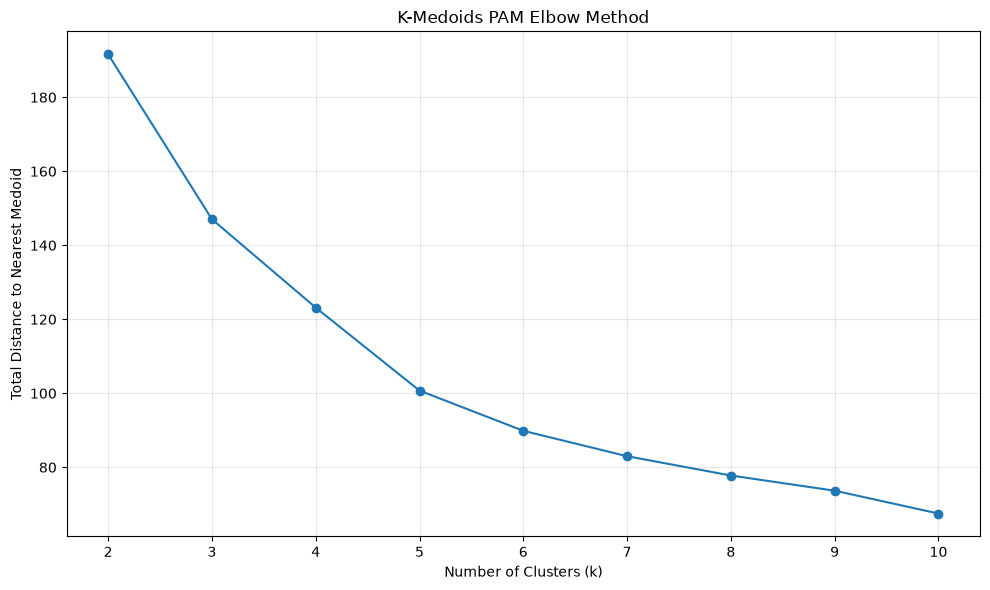

In [34]:
# ============================================
# K-MEDOIDS ELBOW / COST CURVE
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    kmedoids_results_df["k"],
    kmedoids_results_df["medoid_cost"],
    marker="o"
)

plt.title("K-Medoids PAM Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Total Distance to Nearest Medoid")
plt.xticks(list(K_VALUES))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

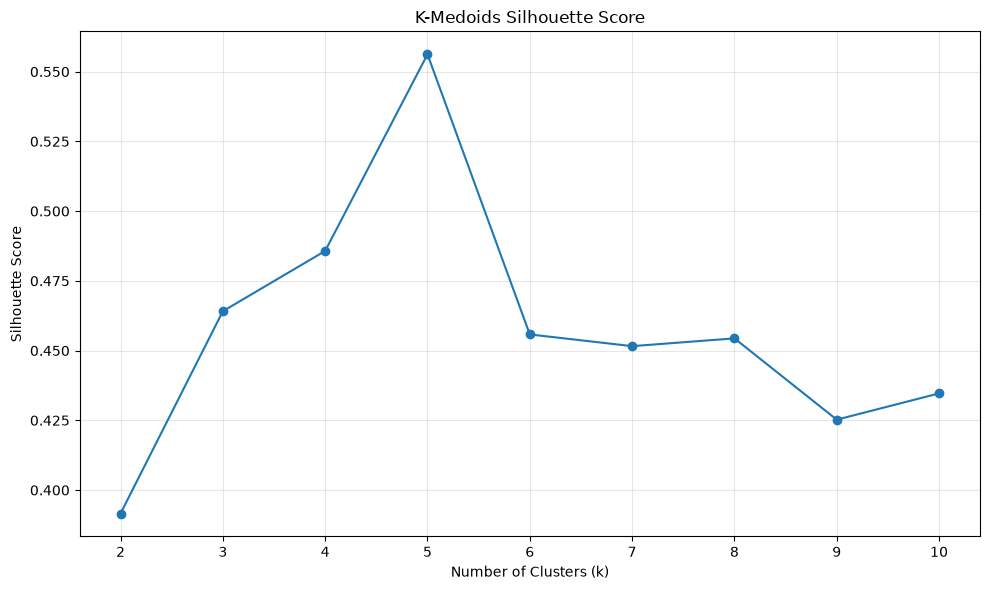

In [35]:
# ============================================
# K-MEDOIDS SILHOUETTE SCORE
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    kmedoids_results_df["k"],
    kmedoids_results_df["silhouette"],
    marker="o"
)

plt.title("K-Medoids Silhouette Score")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(K_VALUES))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

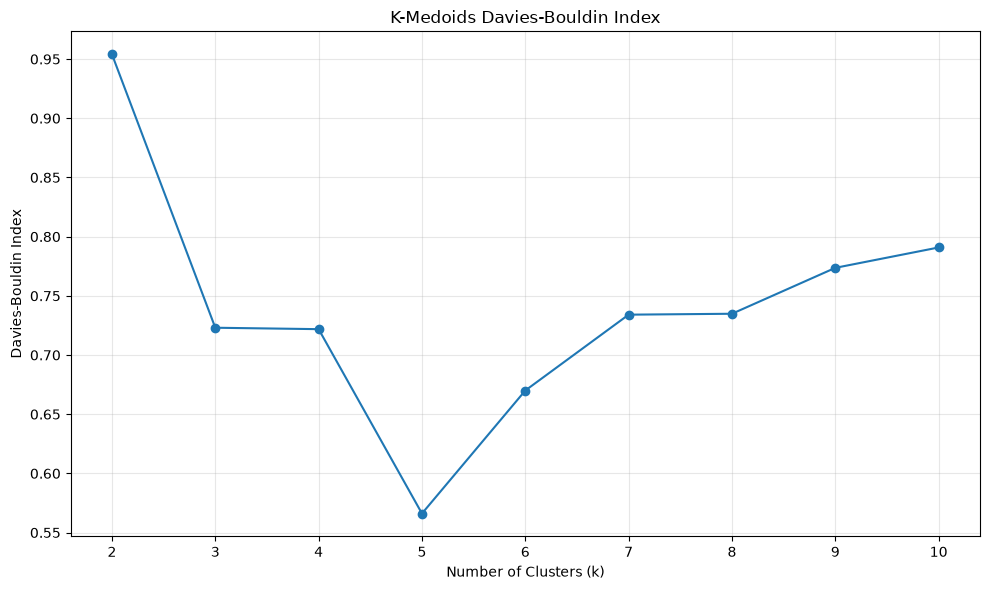

In [36]:
# ============================================
# K-MEDOIDS DAVIES-BOULDIN INDEX
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    kmedoids_results_df["k"],
    kmedoids_results_df["davies_bouldin"],
    marker="o"
)

plt.title("K-Medoids Davies-Bouldin Index")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Davies-Bouldin Index")
plt.xticks(list(K_VALUES))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
# ============================================
# K-MEDOIDS METRIC SUMMARY
# ============================================

best_kmedoids_silhouette_k = kmedoids_results_df.loc[
    kmedoids_results_df["silhouette"].idxmax(),
    "k"
]

best_kmedoids_db_k = kmedoids_results_df.loc[
    kmedoids_results_df["davies_bouldin"].idxmin(),
    "k"
]

print(
    "K with highest K-Medoids silhouette:",
    best_kmedoids_silhouette_k
)

print(
    "K with lowest K-Medoids Davies-Bouldin:",
    best_kmedoids_db_k
)

K with highest K-Medoids silhouette: 5
K with lowest K-Medoids Davies-Bouldin: 5


In [38]:
# ============================================
# SAVE K-MEDOIDS RESULTS
# ============================================

kmedoids_results_df.to_csv(
    RESULTS_PATH / "kmedoids_optimal_k_results.csv",
    index=False
)

print("K-Medoids optimal-k results saved.")

K-Medoids optimal-k results saved.


In [39]:
display(kmedoids_results_df)

,k,medoid_cost,silhouette,davies_bouldin
0,2,191.620090,0.391585,0.954039
1,3,147.039435,0.464115,0.723047
2,4,123.154845,0.485719,0.721844
3,5,100.720375,0.556218,0.566089
4,6,89.852574,0.455792,0.670017
5,7,82.986177,0.451588,0.734088
6,8,77.770731,0.454380,0.734855
7,9,73.665180,0.425235,0.773644
8,10,67.493892,0.434654,0.790854


In [40]:
# ============================================
# FINAL K-MEANS MODEL
# ============================================

OPTIMAL_K = 5

final_kmeans = KMeans(
    n_clusters=OPTIMAL_K,
    init="k-means++",
    n_init=20,
    random_state=42
)

kmeans_labels = final_kmeans.fit_predict(X_scaled)

df["KMeans_Cluster"] = kmeans_labels

print("Final K-Means model trained.")
print("Number of clusters:", OPTIMAL_K)

print("\nCluster sizes:")
print(
    df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

Final K-Means model trained.
Number of clusters: 5

Cluster sizes:
KMeans_Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [41]:
# ============================================
# K-MEANS CENTROIDS
# ============================================

kmeans_centroids_scaled = pd.DataFrame(
    final_kmeans.cluster_centers_,
    columns=CLUSTER_FEATURES
)

print("K-Means centroids in standardized space:")
display(kmeans_centroids_scaled)

K-Means centroids in standardized space:


,Annual Income (k$),Spending Score (1-100)
0,-0.200913,-0.026456
1,0.991583,1.239503
2,-1.329545,1.132178
3,1.055003,-1.284439
4,-1.307519,-1.136965


In [42]:
kmeans_centroids_original = pd.DataFrame(
    scaler.inverse_transform(
        final_kmeans.cluster_centers_
    ),
    columns=CLUSTER_FEATURES
)

kmeans_centroids_original.index.name = "Cluster"

print("K-Means centroids in original units:")
display(kmeans_centroids_original)

K-Means centroids in original units:


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.296296,49.518519
1,86.538462,82.128205
2,25.727273,79.363636
3,88.200000,17.114286
4,26.304348,20.913043


In [43]:
# ============================================
# FINAL K-MEDOIDS MODEL
# ============================================

final_medoids, medoid_labels, final_medoid_cost = pam_kmedoids(
    X_scaled.values,
    k=OPTIMAL_K
)

df["KMedoids_Cluster"] = medoid_labels

print("Final K-Medoids model trained.")
print("Number of clusters:", OPTIMAL_K)

print("\nCluster sizes:")
print(
    df["KMedoids_Cluster"]
    .value_counts()
    .sort_index()
)

Final K-Medoids model trained.
Number of clusters: 5

Cluster sizes:
KMedoids_Cluster
0    84
1    39
2    35
3    21
4    21
Name: count, dtype: int64


In [44]:
# ============================================
# K-MEDOIDS - ACTUAL MEDOID CUSTOMERS
# ============================================

medoid_customers = df.iloc[final_medoids].copy()

medoid_customers = medoid_customers[
    [
        "CustomerID",
        "Gender",
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
]

display(medoid_customers)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
80,81,Male,57,54,51
161,162,Female,29,79,83
176,177,Male,58,88,15
15,16,Male,22,20,79
24,25,Female,54,28,14


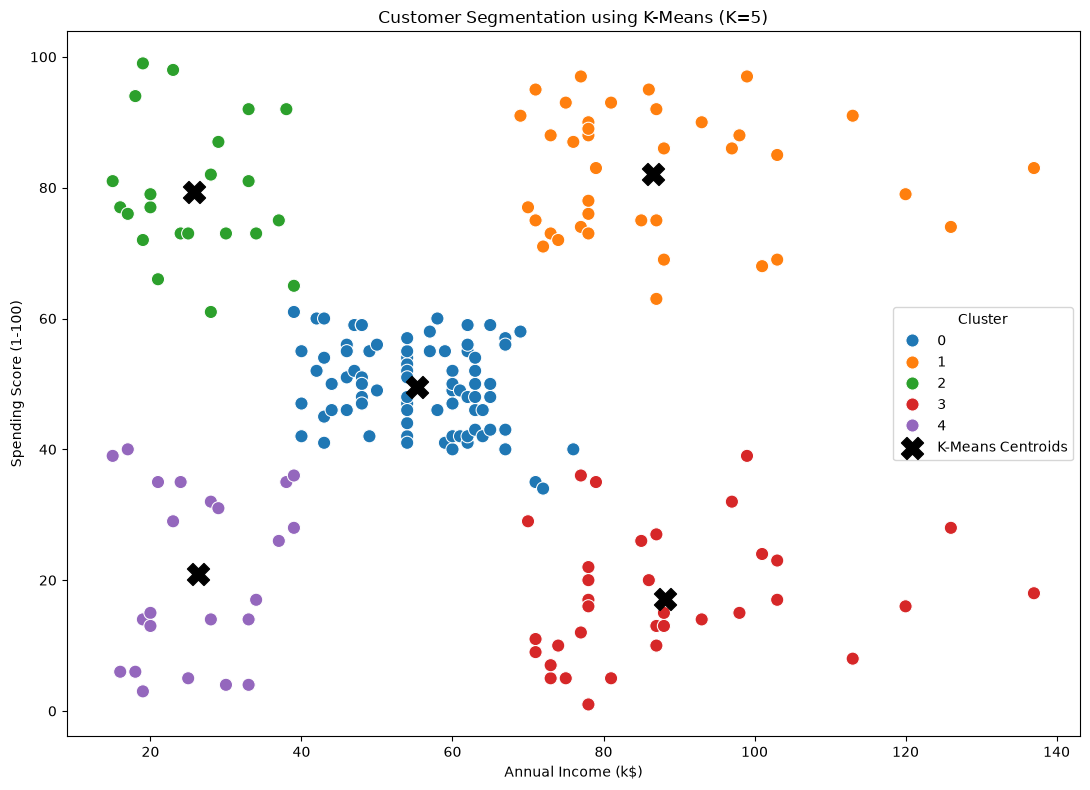

In [45]:
# ============================================
# K-MEANS CLUSTER VISUALIZATION
# ============================================

plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Cluster",
    palette="tab10",
    s=90
)

plt.scatter(
    kmeans_centroids_original["Annual Income (k$)"],
    kmeans_centroids_original["Spending Score (1-100)"],
    marker="X",
    s=250,
    color="black",
    label="K-Means Centroids"
)

plt.title("Customer Segmentation using K-Means (K=5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

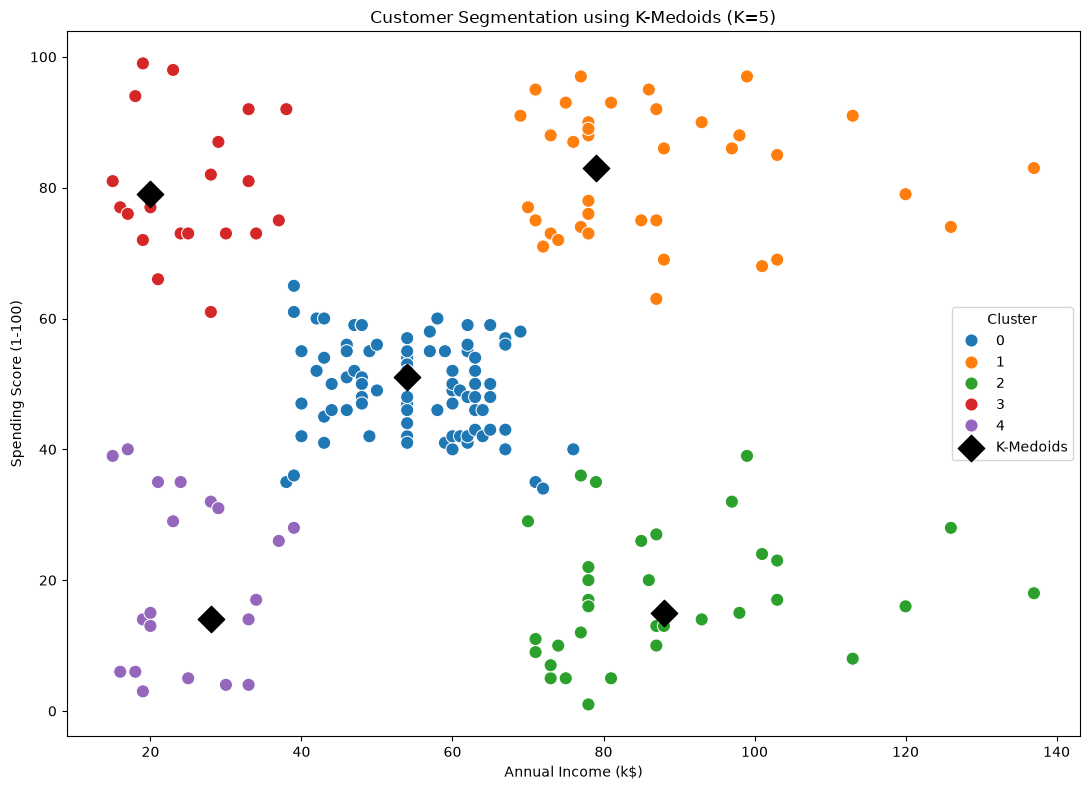

In [46]:
# ============================================
# K-MEDOIDS CLUSTER VISUALIZATION
# ============================================

plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMedoids_Cluster",
    palette="tab10",
    s=90
)

plt.scatter(
    df.iloc[final_medoids]["Annual Income (k$)"],
    df.iloc[final_medoids]["Spending Score (1-100)"],
    marker="D",
    s=180,
    color="black",
    label="K-Medoids"
)

plt.title("Customer Segmentation using K-Medoids (K=5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [47]:
# ============================================
# K-MEANS CLUSTER PROFILING
# ============================================

kmeans_profile = (
    df.groupby("KMeans_Cluster")
    .agg(
        Customers=("CustomerID", "count"),
        Avg_Age=("Age", "mean"),
        Median_Age=("Age", "median"),
        Avg_Income=("Annual Income (k$)", "mean"),
        Median_Income=("Annual Income (k$)", "median"),
        Avg_Spending=("Spending Score (1-100)", "mean"),
        Median_Spending=("Spending Score (1-100)", "median")
    )
    .round(2)
)

kmeans_profile["Percentage"] = (
    kmeans_profile["Customers"] / len(df) * 100
).round(2)

display(kmeans_profile)

,Customers,Avg_Age,Median_Age,Avg_Income,Median_Income,Avg_Spending,Median_Spending,Percentage
KMeans_Cluster,,,,,,,,
0,81,42.72,46.0,55.30,54.0,49.52,50.0,40.5
1,39,32.69,32.0,86.54,79.0,82.13,83.0,19.5
2,22,25.27,23.5,25.73,24.5,79.36,77.0,11.0
3,35,41.11,42.0,88.20,85.0,17.11,16.0,17.5
4,23,45.22,46.0,26.30,25.0,20.91,17.0,11.5


In [48]:
# ============================================
# K-MEANS GENDER PROFILE
# ============================================

kmeans_gender = pd.crosstab(
    df["KMeans_Cluster"],
    df["Gender"],
    normalize="index"
) * 100

kmeans_gender = kmeans_gender.round(2)

display(kmeans_gender)

Gender,Female,Male
KMeans_Cluster,,
0,59.26,40.74
1,53.85,46.15
2,59.09,40.91
3,45.71,54.29
4,60.87,39.13


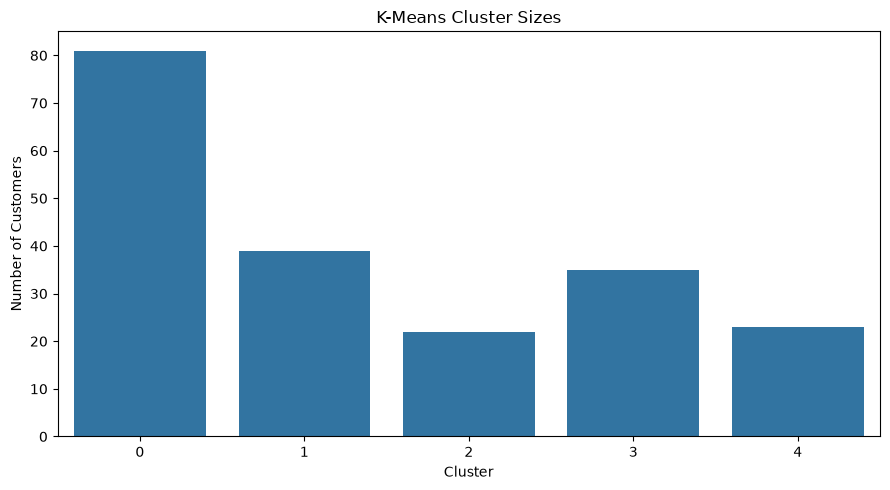

In [49]:
# ============================================
# K-MEANS CLUSTER SIZE
# ============================================

cluster_counts = (
    df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title("K-Means Cluster Sizes")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

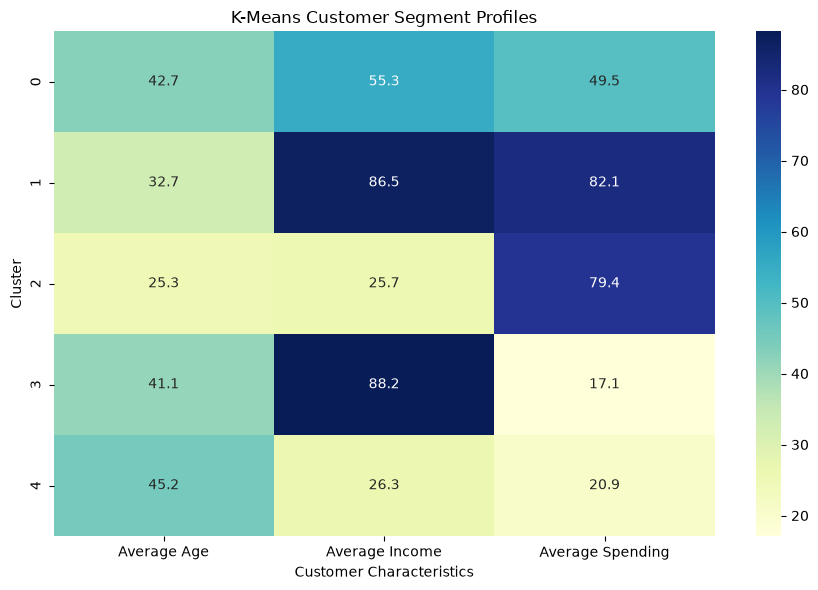

In [50]:
# ============================================
# K-MEANS PROFILE HEATMAP
# ============================================

profile_features = [
    "Avg_Age",
    "Avg_Income",
    "Avg_Spending"
]

profile_heatmap = kmeans_profile[profile_features].copy()

profile_heatmap.columns = [
    "Average Age",
    "Average Income",
    "Average Spending"
]

plt.figure(figsize=(9, 6))

sns.heatmap(
    profile_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("K-Means Customer Segment Profiles")
plt.xlabel("Customer Characteristics")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

In [51]:
# ============================================
# K-MEANS SEGMENT INTERPRETATION
# ============================================

income_median = df["Annual Income (k$)"].median()
spending_median = df["Spending Score (1-100)"].median()

print("Overall median income:", income_median)
print("Overall median spending score:", spending_median)

Overall median income: 61.5
Overall median spending score: 50.0


In [52]:
def classify_segment(avg_income, avg_spending):
    if (
        avg_income >= income_median
        and avg_spending >= spending_median
    ):
        return "High Income - High Spending"

    elif (
        avg_income >= income_median
        and avg_spending < spending_median
    ):
        return "High Income - Low Spending"

    elif (
        avg_income < income_median
        and avg_spending >= spending_median
    ):
        return "Low Income - High Spending"

    else:
        return "Low Income - Low Spending"

In [53]:
kmeans_profile["Segment_Type"] = kmeans_profile.apply(
    lambda row: classify_segment(
        row["Avg_Income"],
        row["Avg_Spending"]
    ),
    axis=1
)

display(kmeans_profile)

,Customers,Avg_Age,Median_Age,Avg_Income,Median_Income,Avg_Spending,Median_Spending,Percentage,Segment_Type
KMeans_Cluster,,,,,,,,,
0,81,42.72,46.0,55.30,54.0,49.52,50.0,40.5,Low Income - Low Spending
1,39,32.69,32.0,86.54,79.0,82.13,83.0,19.5,High Income - High Spending
2,22,25.27,23.5,25.73,24.5,79.36,77.0,11.0,Low Income - High Spending
3,35,41.11,42.0,88.20,85.0,17.11,16.0,17.5,High Income - Low Spending
4,23,45.22,46.0,26.30,25.0,20.91,17.0,11.5,Low Income - Low Spending


In [54]:
# ============================================
# K-MEDOIDS CLUSTER PROFILING
# ============================================

kmedoids_profile = (
    df.groupby("KMedoids_Cluster")
    .agg(
        Customers=("CustomerID", "count"),
        Avg_Age=("Age", "mean"),
        Median_Age=("Age", "median"),
        Avg_Income=("Annual Income (k$)", "mean"),
        Median_Income=("Annual Income (k$)", "median"),
        Avg_Spending=("Spending Score (1-100)", "mean"),
        Median_Spending=("Spending Score (1-100)", "median")
    )
    .round(2)
)

kmedoids_profile["Percentage"] = (
    kmedoids_profile["Customers"] / len(df) * 100
).round(2)

display(kmedoids_profile)

,Customers,Avg_Age,Median_Age,Avg_Income,Median_Income,Avg_Spending,Median_Spending,Percentage
KMedoids_Cluster,,,,,,,,
0,84,42.82,46.5,54.70,54.0,49.37,49.5,42.0
1,39,32.69,32.0,86.54,79.0,82.13,83.0,19.5
2,35,41.11,42.0,88.20,85.0,17.11,16.0,17.5
3,21,25.33,23.0,25.10,24.0,80.05,77.0,10.5
4,21,44.14,45.0,25.14,24.0,19.52,15.0,10.5


In [55]:
# ============================================
# K-MEDOIDS GENDER PROFILE
# ============================================

kmedoids_gender = pd.crosstab(
    df["KMedoids_Cluster"],
    df["Gender"],
    normalize="index"
) * 100

kmedoids_gender = kmedoids_gender.round(2)

display(kmedoids_gender)

Gender,Female,Male
KMedoids_Cluster,,
0,59.52,40.48
1,53.85,46.15
2,45.71,54.29
3,57.14,42.86
4,61.90,38.10


In [56]:
# ============================================
# K-MEANS VS K-MEDOIDS AGREEMENT
# ============================================

from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    kmeans_labels,
    medoid_labels
)

print("Adjusted Rand Index:", round(ari, 4))

Adjusted Rand Index: 0.9597


In [57]:
# ============================================
# CLUSTER ASSIGNMENT CONTINGENCY TABLE
# ============================================

cluster_comparison = pd.crosstab(
    df["KMeans_Cluster"],
    df["KMedoids_Cluster"]
)

display(cluster_comparison)

KMedoids_Cluster,0,1,2,3,4
KMeans_Cluster,,,,,
0,81,0,0,0,0
1,0,39,0,0,0
2,1,0,0,21,0
3,0,0,35,0,0
4,2,0,0,0,21


In [58]:
# ============================================
# FINAL ALGORITHM COMPARISON
# ============================================

final_comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "K-Medoids (PAM)"
    ],
    "K": [
        OPTIMAL_K,
        OPTIMAL_K
    ],
    "Silhouette": [
        silhouette_score(X_scaled, kmeans_labels),
        silhouette_score(X_scaled, medoid_labels)
    ],
    "Davies-Bouldin": [
        davies_bouldin_score(X_scaled, kmeans_labels),
        davies_bouldin_score(X_scaled, medoid_labels)
    ],
    "Objective": [
        final_kmeans.inertia_,
        final_medoid_cost
    ]
})

final_comparison = final_comparison.round(4)

display(final_comparison)

,Algorithm,K,Silhouette,Davies-Bouldin,Objective
0,K-Means,5,0.5547,0.5722,65.5684
1,K-Medoids (PAM),5,0.5562,0.5661,100.7204


In [59]:
# ============================================
# SAVE FINAL RESULTS
# ============================================

kmeans_profile.to_csv(
    RESULTS_PATH / "kmeans_cluster_profiles.csv"
)

kmedoids_profile.to_csv(
    RESULTS_PATH / "kmedoids_cluster_profiles.csv"
)

final_comparison.to_csv(
    RESULTS_PATH / "final_algorithm_comparison.csv",
    index=False
)

cluster_comparison.to_csv(
    RESULTS_PATH / "cluster_assignment_comparison.csv"
)

df.to_csv(
    PROCESSED_PATH / "customers_with_cluster_assignments.csv",
    index=False
)

print("All final clustering results saved successfully.")

All final clustering results saved successfully.


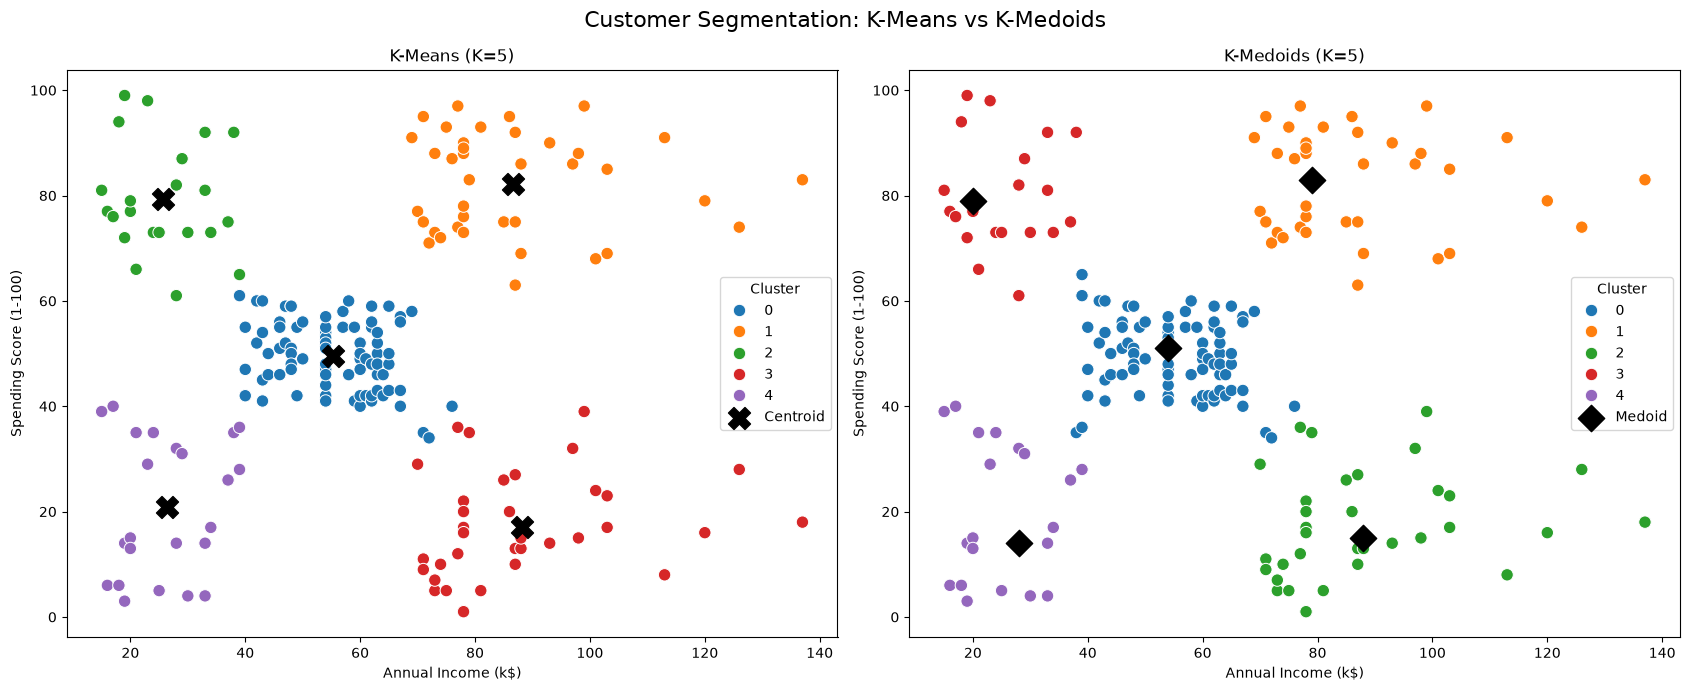

In [60]:
# ============================================
# K-MEANS VS K-MEDOIDS VISUAL COMPARISON
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# --------------------------------------------
# K-MEANS
# --------------------------------------------

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Cluster",
    palette="tab10",
    s=80,
    ax=axes[0]
)

axes[0].scatter(
    kmeans_centroids_original["Annual Income (k$)"],
    kmeans_centroids_original["Spending Score (1-100)"],
    marker="X",
    s=250,
    color="black",
    label="Centroid"
)

axes[0].set_title("K-Means (K=5)")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].legend(title="Cluster")

# --------------------------------------------
# K-MEDOIDS
# --------------------------------------------

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMedoids_Cluster",
    palette="tab10",
    s=80,
    ax=axes[1]
)

axes[1].scatter(
    df.iloc[final_medoids]["Annual Income (k$)"],
    df.iloc[final_medoids]["Spending Score (1-100)"],
    marker="D",
    s=180,
    color="black",
    label="Medoid"
)

axes[1].set_title("K-Medoids (K=5)")
axes[1].set_xlabel("Annual Income (k$)")
axes[1].set_ylabel("Spending Score (1-100)")
axes[1].legend(title="Cluster")

plt.suptitle(
    "Customer Segmentation: K-Means vs K-Medoids",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [61]:
# ============================================
# FINAL BUSINESS SEGMENT NAMES
# ============================================

KMEANS_SEGMENT_NAMES = {
    0: "Balanced / Moderate Customers",
    1: "High-Value Customers",
    2: "High-Spending Budget Customers",
    3: "High-Income Low-Spending Customers",
    4: "Low-Engagement Customers"
}

KMEDOIDS_SEGMENT_NAMES = {
    0: "Balanced / Moderate Customers",
    1: "High-Value Customers",
    2: "High-Income Low-Spending Customers",
    3: "High-Spending Budget Customers",
    4: "Low-Engagement Customers"
}

df["KMeans_Segment"] = df["KMeans_Cluster"].map(
    KMEANS_SEGMENT_NAMES
)

df["KMedoids_Segment"] = df["KMedoids_Cluster"].map(
    KMEDOIDS_SEGMENT_NAMES
)

display(
    df[
        [
            "CustomerID",
            "KMeans_Cluster",
            "KMeans_Segment",
            "KMedoids_Cluster",
            "KMedoids_Segment"
        ]
    ].head(10)
)

,CustomerID,KMeans_Cluster,KMeans_Segment,KMedoids_Cluster,KMedoids_Segment
0,1,4,Low-Engagement Customers,4,Low-Engagement Customers
1,2,2,High-Spending Budget Customers,3,High-Spending Budget Customers
2,3,4,Low-Engagement Customers,4,Low-Engagement Customers
3,4,2,High-Spending Budget Customers,3,High-Spending Budget Customers
4,5,4,Low-Engagement Customers,4,Low-Engagement Customers
5,6,2,High-Spending Budget Customers,3,High-Spending Budget Customers
6,7,4,Low-Engagement Customers,4,Low-Engagement Customers
7,8,2,High-Spending Budget Customers,3,High-Spending Budget Customers
8,9,4,Low-Engagement Customers,4,Low-Engagement Customers
9,10,2,High-Spending Budget Customers,3,High-Spending Budget Customers


In [62]:
# ============================================
# FINAL K-MEANS BUSINESS PROFILE
# ============================================

business_profile = (
    df.groupby(["KMeans_Cluster", "KMeans_Segment"])
    .agg(
        Customers=("CustomerID", "count"),
        Avg_Age=("Age", "mean"),
        Avg_Income=("Annual Income (k$)", "mean"),
        Avg_Spending=("Spending Score (1-100)", "mean")
    )
    .reset_index()
)

business_profile["Percentage"] = (
    business_profile["Customers"] / len(df) * 100
)

business_profile = business_profile.round(2)

display(business_profile)

,KMeans_Cluster,KMeans_Segment,Customers,Avg_Age,Avg_Income,Avg_Spending,Percentage
0,0,Balanced / Moderate Customers,81,42.72,55.30,49.52,40.5
1,1,High-Value Customers,39,32.69,86.54,82.13,19.5
2,2,High-Spending Budget Customers,22,25.27,25.73,79.36,11.0
3,3,High-Income Low-Spending Customers,35,41.11,88.20,17.11,17.5
4,4,Low-Engagement Customers,23,45.22,26.30,20.91,11.5


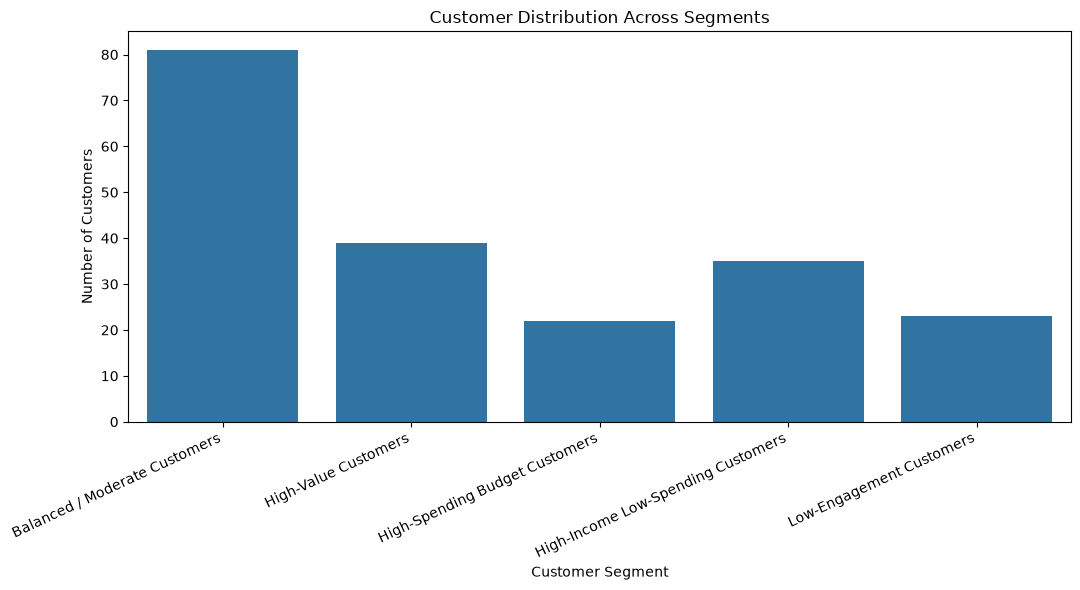

In [63]:
# ============================================
# CUSTOMER SEGMENT SIZES
# ============================================

plot_data = business_profile.copy()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_data,
    x="KMeans_Segment",
    y="Customers"
)

plt.title("Customer Distribution Across Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [64]:
# ============================================
# SEGMENT INSIGHT TABLE
# ============================================

segment_insights = pd.DataFrame({
    "Segment": [
        "Balanced / Moderate Customers",
        "High-Value Customers",
        "High-Spending Budget Customers",
        "High-Income Low-Spending Customers",
        "Low-Engagement Customers"
    ],
    "Interpretation": [
        "Customers with moderate income and moderate spending behavior.",
        "Customers with relatively high income and high spending scores.",
        "Customers with lower income but relatively high spending scores.",
        "Customers with high income but relatively low spending scores.",
        "Customers with relatively low income and low spending scores."
    ],
    "Potential Strategy": [
        "Maintain engagement and offer personalized promotions.",
        "Prioritize loyalty programs, premium offers and retention.",
        "Use affordable promotions and value-oriented campaigns.",
        "Investigate barriers to spending and use targeted engagement.",
        "Use introductory offers and engagement campaigns."
    ]
})

display(segment_insights)

,Segment,Interpretation,Potential Strategy
0,Balanced / Moderate Customers,Customers with moderate income and moderate sp...,Maintain engagement and offer personalized pro...
1,High-Value Customers,Customers with relatively high income and high...,"Prioritize loyalty programs, premium offers an..."
2,High-Spending Budget Customers,Customers with lower income but relatively hig...,Use affordable promotions and value-oriented c...
3,High-Income Low-Spending Customers,Customers with high income but relatively low ...,Investigate barriers to spending and use targe...
4,Low-Engagement Customers,Customers with relatively low income and low s...,Use introductory offers and engagement campaigns.


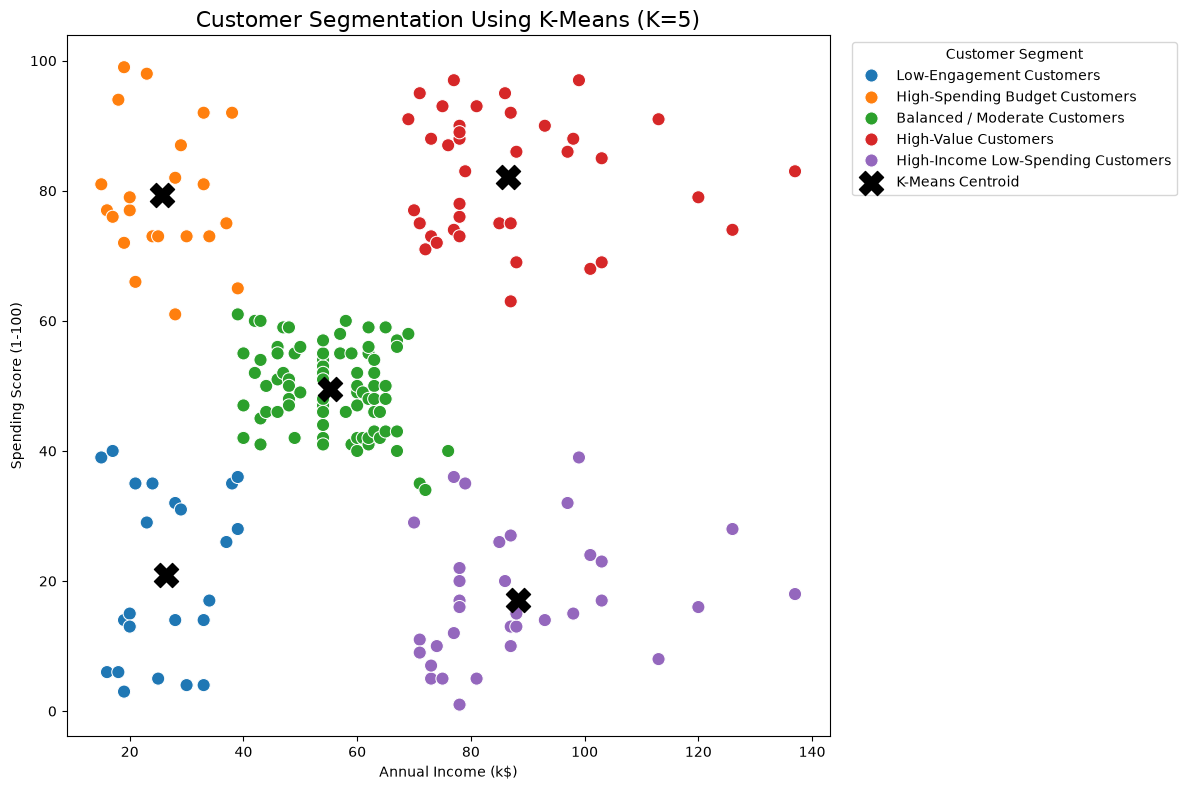

In [65]:
# ============================================
# LABELED CUSTOMER SEGMENTATION
# ============================================

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Segment",
    s=90,
    palette="tab10"
)

plt.scatter(
    kmeans_centroids_original["Annual Income (k$)"],
    kmeans_centroids_original["Spending Score (1-100)"],
    marker="X",
    s=300,
    color="black",
    label="K-Means Centroid"
)

plt.title(
    "Customer Segmentation Using K-Means (K=5)",
    fontsize=16
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.legend(
    title="Customer Segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

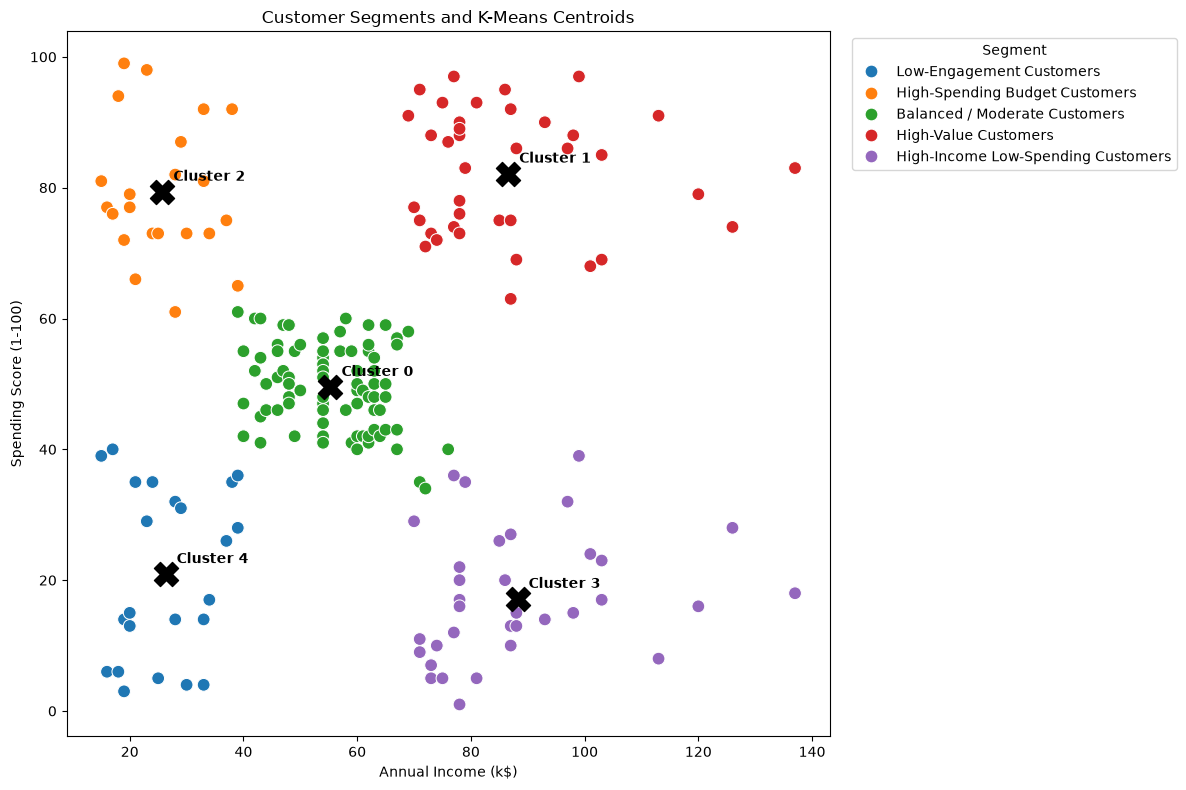

In [66]:
# ============================================
# ANNOTATED K-MEANS SEGMENTS
# ============================================

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Segment",
    s=85,
    palette="tab10"
)

for cluster_id, centroid in kmeans_centroids_original.iterrows():

    plt.scatter(
        centroid["Annual Income (k$)"],
        centroid["Spending Score (1-100)"],
        marker="X",
        s=300,
        color="black"
    )

    plt.annotate(
        f"Cluster {cluster_id}",
        (
            centroid["Annual Income (k$)"],
            centroid["Spending Score (1-100)"]
        ),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Customer Segments and K-Means Centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.legend(
    title="Segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [67]:
# ============================================
# SAVE FIGURE DIRECTORY
# ============================================

FIGURES_PATH = Path("../artifacts/figures")
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

print("Figure directory ready:", FIGURES_PATH)

Figure directory ready: ..\artifacts\figures


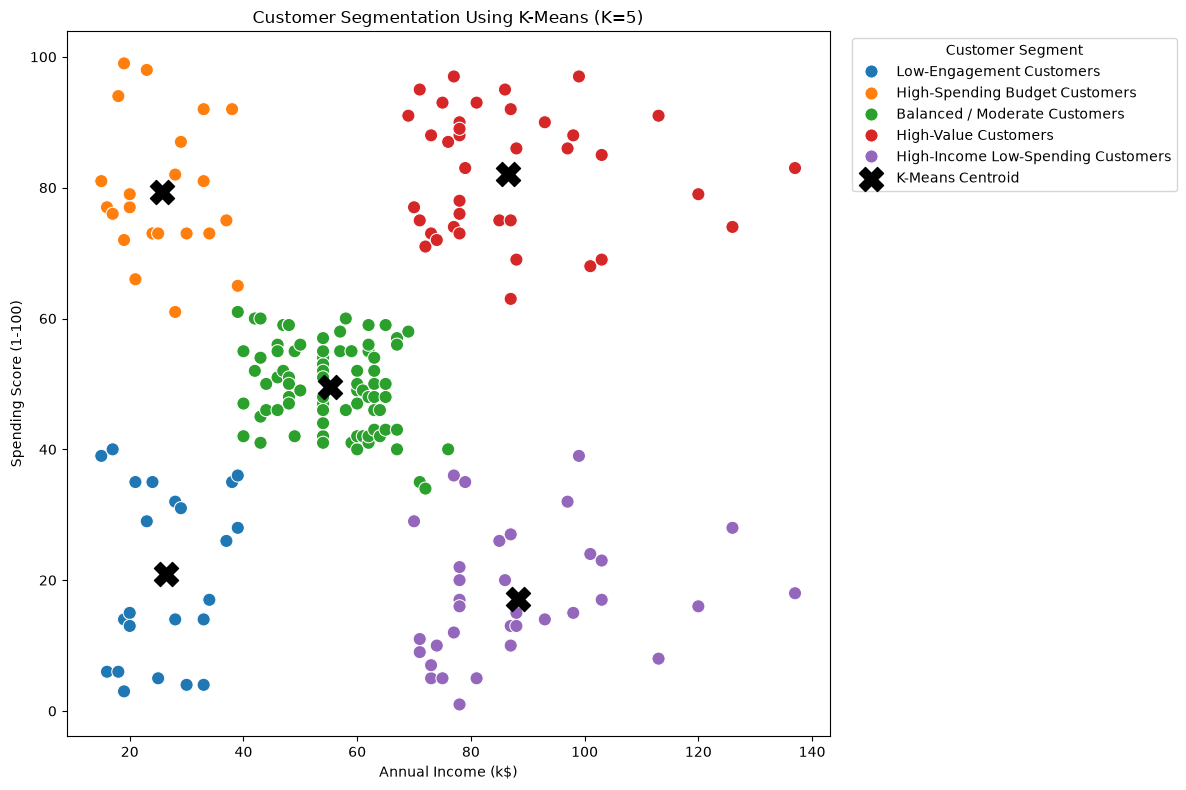

In [68]:
# ============================================
# SAVE MAIN SEGMENTATION FIGURE
# ============================================

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Segment",
    s=90,
    palette="tab10"
)

plt.scatter(
    kmeans_centroids_original["Annual Income (k$)"],
    kmeans_centroids_original["Spending Score (1-100)"],
    marker="X",
    s=300,
    color="black",
    label="K-Means Centroid"
)

plt.title("Customer Segmentation Using K-Means (K=5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.legend(
    title="Customer Segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "kmeans_customer_segmentation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [69]:
business_profile.to_csv(
    RESULTS_PATH / "final_business_segment_profile.csv",
    index=False
)

segment_insights.to_csv(
    RESULTS_PATH / "segment_business_insights.csv",
    index=False
)

df.to_csv(
    PROCESSED_PATH / "final_customer_segmentation.csv",
    index=False
)

print("Final business analysis saved successfully.")

Final business analysis saved successfully.


In [70]:
# ============================================
# RUNTIME COMPARISON
# ============================================

import time

# K-Means
start = time.perf_counter()

benchmark_kmeans = KMeans(
    n_clusters=OPTIMAL_K,
    init="k-means++",
    n_init=20,
    random_state=42
)

benchmark_kmeans.fit(X_scaled)

kmeans_runtime = time.perf_counter() - start


# K-Medoids
start = time.perf_counter()

benchmark_medoids, benchmark_labels, benchmark_cost = pam_kmedoids(
    X_scaled.values,
    k=OPTIMAL_K
)

kmedoids_runtime = time.perf_counter() - start


runtime_comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "K-Medoids (PAM)"
    ],
    "Runtime_seconds": [
        kmeans_runtime,
        kmedoids_runtime
    ]
})

runtime_comparison["Runtime_seconds"] = (
    runtime_comparison["Runtime_seconds"].round(6)
)

display(runtime_comparison)

,Algorithm,Runtime_seconds
0,K-Means,0.164474
1,K-Medoids (PAM),0.076011


In [71]:
# ============================================
# FINAL ALGORITHM SCORECARD
# ============================================

final_scorecard = pd.DataFrame({
    "Metric": [
        "Optimal K",
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Runtime (seconds)",
        "Cluster Agreement (ARI)"
    ],
    "K-Means": [
        OPTIMAL_K,
        silhouette_score(X_scaled, kmeans_labels),
        davies_bouldin_score(X_scaled, kmeans_labels),
        kmeans_runtime,
        np.nan
    ],
    "K-Medoids (PAM)": [
        OPTIMAL_K,
        silhouette_score(X_scaled, medoid_labels),
        davies_bouldin_score(X_scaled, medoid_labels),
        kmedoids_runtime,
        np.nan
    ]
})

display(final_scorecard.round(4))

,Metric,K-Means,K-Medoids (PAM)
0,Optimal K,5.0000,5.0000
1,Silhouette Score,0.5547,0.5562
2,Davies-Bouldin Index,0.5722,0.5661
3,Runtime (seconds),0.1645,0.0760
4,Cluster Agreement (ARI),NaN,NaN


In [72]:
print(f"Adjusted Rand Index: {ari:.4f}")

Adjusted Rand Index: 0.9597


In [73]:
# ============================================
# MODEL ARTIFACT DIRECTORY
# ============================================

MODELS_PATH = Path("../artifacts/models")
MODELS_PATH.mkdir(parents=True, exist_ok=True)

print("Model directory:", MODELS_PATH)

Model directory: ..\artifacts\models


In [74]:
# ============================================
# SAVE K-MEANS MODEL + SCALER
# ============================================

import joblib

joblib.dump(
    scaler,
    MODELS_PATH / "scaler.joblib"
)

joblib.dump(
    final_kmeans,
    MODELS_PATH / "kmeans_k5.joblib"
)

print("Scaler saved.")
print("K-Means model saved.")

Scaler saved.
K-Means model saved.


In [75]:
# ============================================
# SAVE K-MEDOIDS MODEL INFORMATION
# ============================================

kmedoids_model_data = {
    "k": OPTIMAL_K,
    "medoid_indices": final_medoids.tolist(),
    "medoid_points_scaled": X_scaled.iloc[final_medoids].values
}

joblib.dump(
    kmedoids_model_data,
    MODELS_PATH / "kmedoids_pam_k5.joblib"
)

print("K-Medoids model information saved.")

K-Medoids model information saved.


In [76]:
# ============================================
# SAVE FEATURE CONFIGURATION
# ============================================

feature_config = {
    "cluster_features": CLUSTER_FEATURES,
    "optimal_k": OPTIMAL_K
}

joblib.dump(
    feature_config,
    MODELS_PATH / "feature_config.joblib"
)

print("Feature configuration saved.")

Feature configuration saved.


In [77]:
# ============================================
# VERIFY MODEL ARTIFACTS
# ============================================

print("Saved model artifacts:")

for file in MODELS_PATH.iterdir():
    print(" -", file.name)

Saved model artifacts:
 - feature_config.joblib
 - kmeans_k5.joblib
 - kmedoids_pam_k5.joblib
 - scaler.joblib


In [78]:
# ============================================
# FINAL DATASET FOR DASHBOARD
# ============================================

dashboard_df = df.copy()

dashboard_df.to_csv(
    PROCESSED_PATH / "customerlens_final.csv",
    index=False
)

print("Dashboard dataset saved.")
print("Rows:", len(dashboard_df))
print("Columns:", len(dashboard_df.columns))

Dashboard dataset saved.
Rows: 200
Columns: 9


In [79]:
# ============================================
# SAVE OPTIMAL-K EXPERIMENT RESULTS
# ============================================

RESULTS_PATH.mkdir(parents=True, exist_ok=True)

kmeans_results_df.to_csv(
    RESULTS_PATH / "kmeans_optimal_k_results.csv",
    index=False
)

kmedoids_results_df.to_csv(
    RESULTS_PATH / "kmedoids_optimal_k_results.csv",
    index=False
)

print("Optimal-K experiment results saved successfully.")
print("\nSaved files:")

print(
    RESULTS_PATH / "kmeans_optimal_k_results.csv"
)

print(
    RESULTS_PATH / "kmedoids_optimal_k_results.csv"
)

Optimal-K experiment results saved successfully.

Saved files:
..\artifacts\results\kmeans_optimal_k_results.csv
..\artifacts\results\kmedoids_optimal_k_results.csv


In [80]:
print("Files in results directory:")

for file in RESULTS_PATH.iterdir():
    print(" -", file.name)

Files in results directory:
 - cluster_assignment_comparison.csv
 - final_algorithm_comparison.csv
 - final_business_segment_profile.csv
 - kmeans_cluster_profiles.csv
 - kmeans_optimal_k_results.csv
 - kmedoids_cluster_profiles.csv
 - kmedoids_optimal_k_results.csv
 - segment_business_insights.csv
